# Fase 8 — Simulação de política de reposição

Forecasting congelado em `3c52827`: **zero fitting ETS e nenhum actual eval**. Somente outputs desta simulação são carregados aqui. Cenários L1/q90, L2/q95 e L3/q98 são hipóteses. O target é cobertura histórica de venda observada normalizada; não é fill rate, OTIF ou garantia de ausência de ruptura. Sem inventário completo, pedidos, fornecedores, custos ou Power BI.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root=Path.cwd()
if not (root/'src').is_dir():
    root=root.parent
sys.path.insert(0,str(root))
import matplotlib.pyplot as plt
from IPython.display import display
from src.reporting.replenishment_report import load_outputs
from src.reporting.replenishment_plots import PLOTS, save_figure
data=load_outputs(root)
assert data['metadata']['n_ets_fits']==0
assert data['metadata']['eval_actuals_read'] is False
assert len(data['simulation'])==150000
display(data['dependence'])

,diagnostic,step,n,value
0,within_fold_lag_correlation,1,900000,0.065042
1,within_fold_lag_correlation,2,750000,0.057623
2,within_fold_lag_correlation,3,600000,0.037049
3,within_fold_lag_correlation,4,450000,0.042002
4,within_fold_lag_correlation,5,300000,0.067097
5,within_fold_lag_correlation,6,150000,0.054657
6,variance_aggregation_ratio,1,150000,1.000000
7,variance_aggregation_ratio,2,150000,1.078643
8,variance_aggregation_ratio,3,150000,1.156390


## 1. Validação temporal

Calibração folds 1–3, escala de 21 erros e rótulos prospectivos. Fold 4 não escolhe nem retuna a política. Gaps negativos permanecem explícitos.

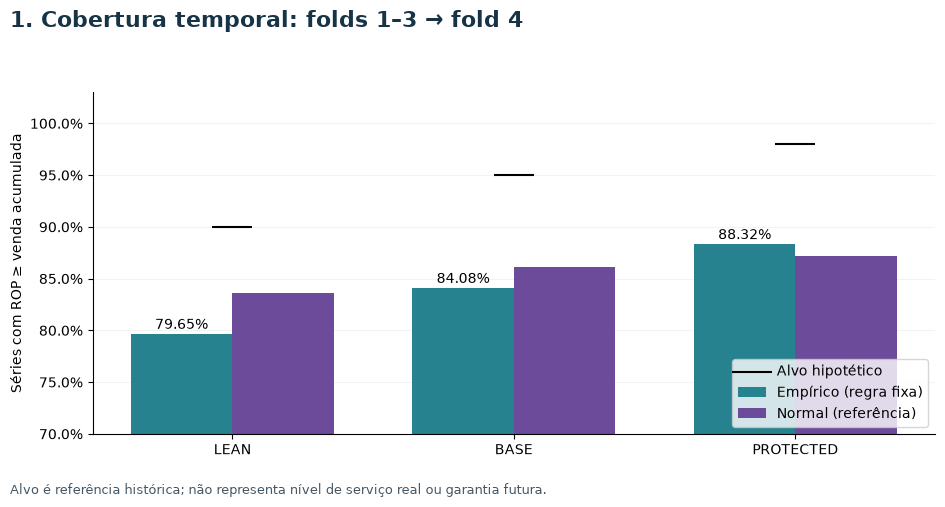

,scenario,target_coverage_level,observed_coverage_rate,coverage_gap,normal_coverage_rate
18,BASE,0.95,0.84084,-0.10916,0.86136
37,LEAN,0.90,0.79648,-0.10352,0.83640
56,PROTECTED,0.98,0.88322,-0.09678,0.87204


In [2]:
fig=PLOTS[0](data)
save_figure(fig,1,root)
plt.show()
display(data['summary'].loc[lambda x: x.stage.eq('validation_fold4') & x.level.eq('global'), ['scenario','target_coverage_level','observed_coverage_rate','coverage_gap','normal_coverage_rate']])


## 2. Multiplicadores finais

Quatro folds de train; Normal é apenas benchmark. Caudas empíricas não representam fill rate ou serviço real.

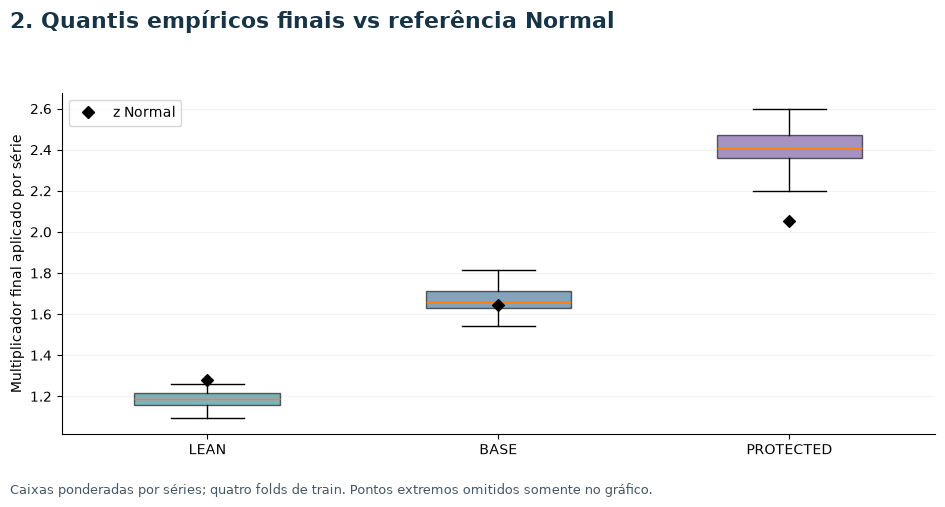

In [3]:
fig=PLOTS[1](data)
save_figure(fig,2,root)
plt.show()


## 3. Safety stock simulado

Reservas hipotéticas na escala normalizada. Não inferir unidades físicas ou demanda latente.

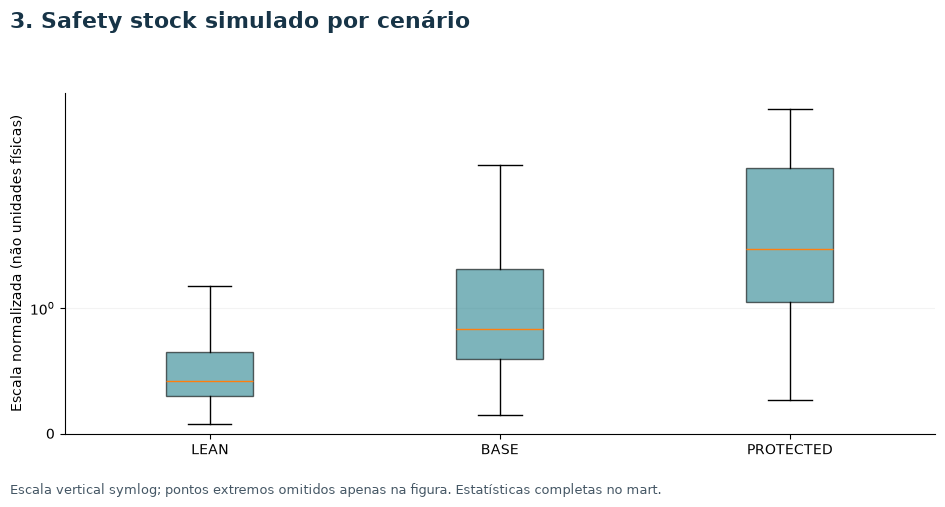

In [4]:
fig=PLOTS[2](data)
save_figure(fig,3,root)
plt.show()


## 4. Reorder point simulado

Limiar = forecast acumulado + buffer. Não é estoque disponível, ordem de compra ou quantidade a comprar.

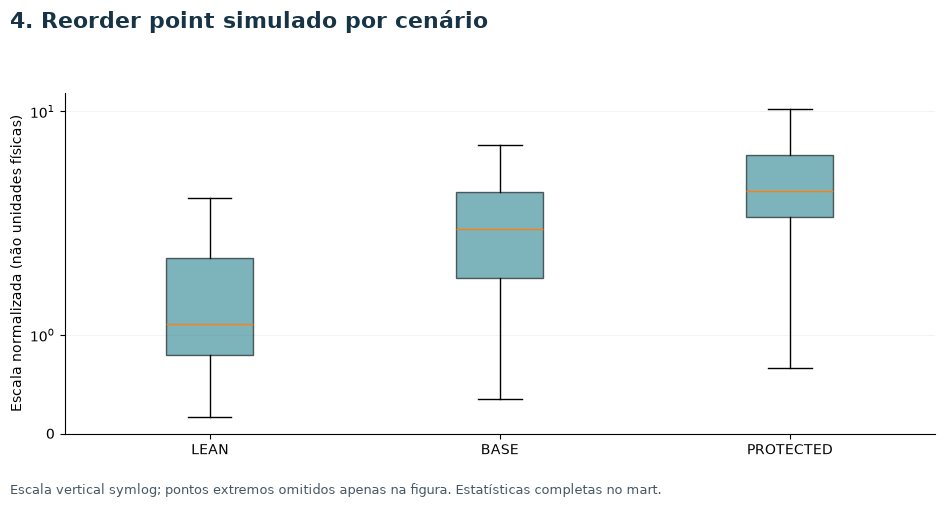

In [5]:
fig=PLOTS[3](data)
save_figure(fig,4,root)
plt.show()


## 5. ABC

Ratios individuais excluem denominadores zero e diferem do ratio de somas. ABC é relevância de venda observada, não receita.

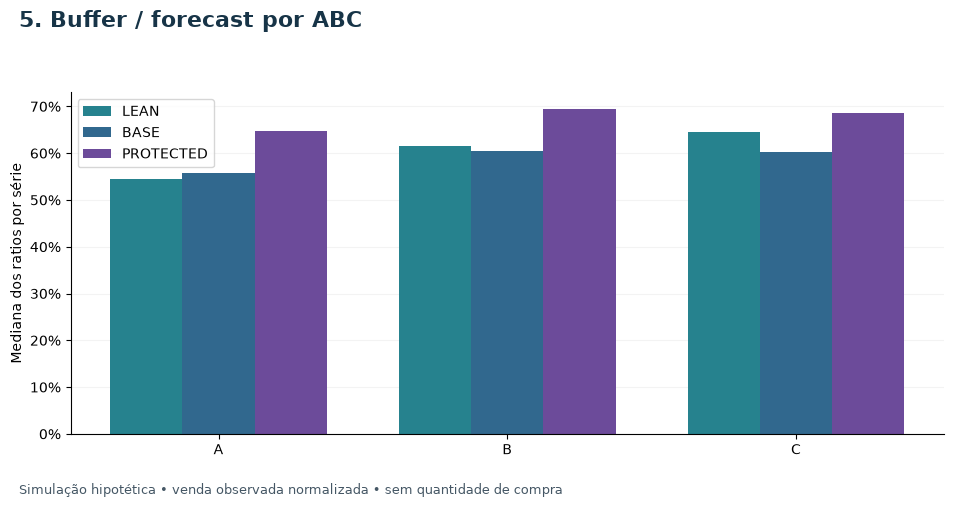

In [6]:
fig=PLOTS[4](data)
save_figure(fig,5,root)
plt.show()


## 6. XYZ

Classes finais conhecidas em 25/06; calibração histórica usa os snapshots prospectivos de cada fold.

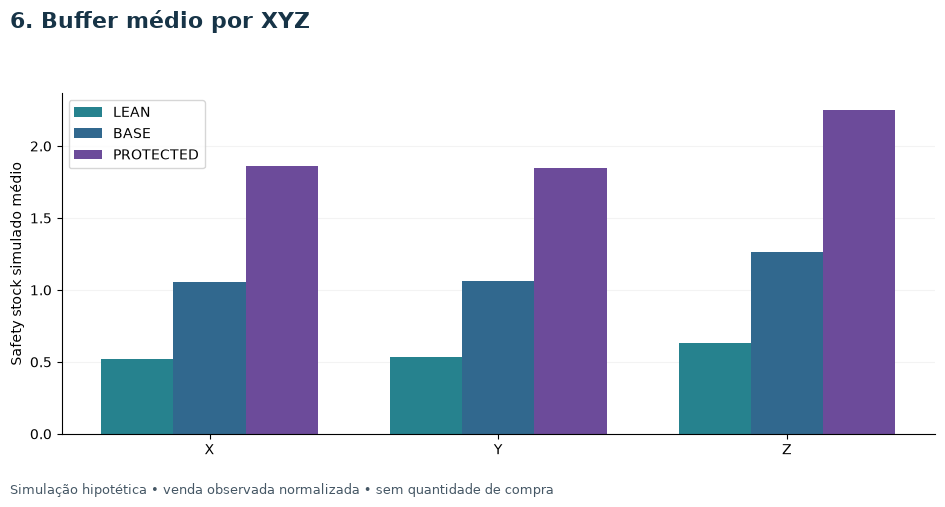

In [7]:
fig=PLOTS[5](data)
save_figure(fig,6,root)
plt.show()


## 7. Exposição

Exposição é dimensão histórica de pooling; flags de censura e persistência não multiplicam buffer.

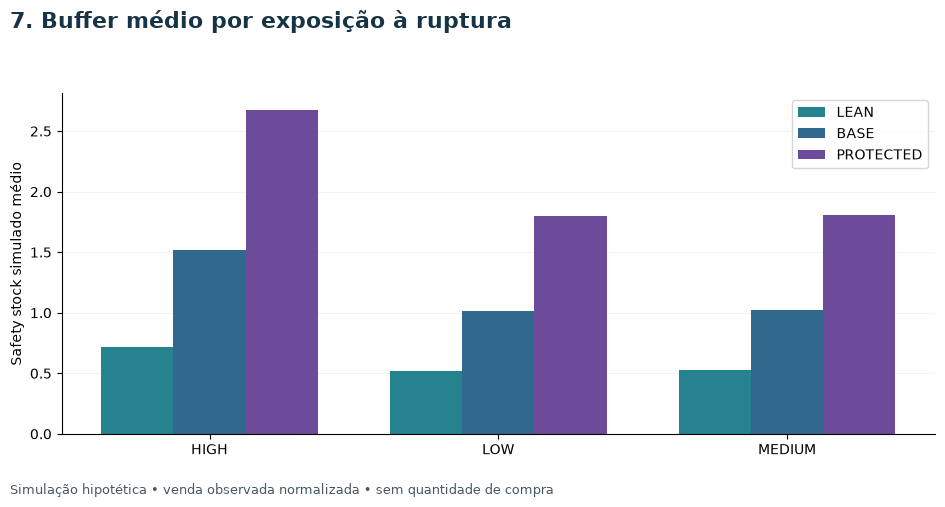

In [8]:
fig=PLOTS[6](data)
save_figure(fig,7,root)
plt.show()


## 8. A e duplo sinal

Investigar coexistência de relevância, incerteza e sinais de observação. Nenhuma compra automática.

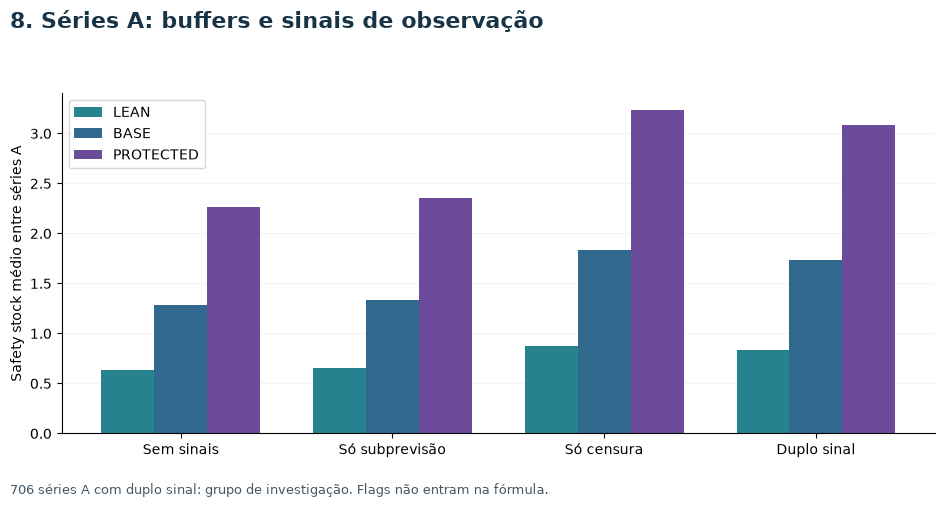

In [9]:
fig=PLOTS[7](data)
save_figure(fig,8,root)
plt.show()


## 9. Suporte e fallback

Hierarquia ABC×XYZ×exposure → ABC×XYZ → XYZ → GLOBAL, mínimo de 20 observações esperadas na cauda; correlação reduz informação efetiva.

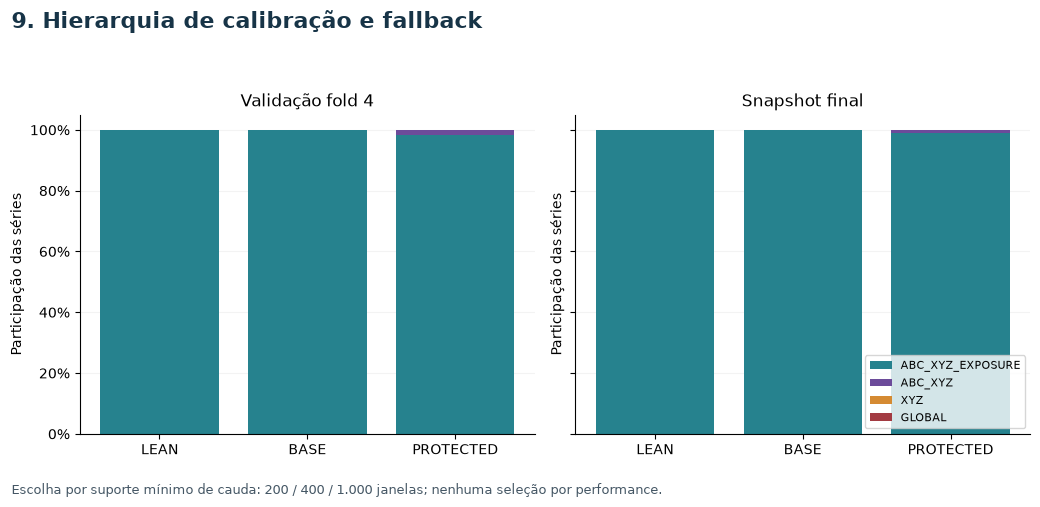

,stage,scenario,calibration_level_used,n_series
0,final_snapshot,BASE,ABC_XYZ_EXPOSURE,50000
1,final_snapshot,LEAN,ABC_XYZ_EXPOSURE,50000
2,final_snapshot,PROTECTED,ABC_XYZ,439
3,final_snapshot,PROTECTED,ABC_XYZ_EXPOSURE,49561
4,validation_fold4,BASE,ABC_XYZ_EXPOSURE,50000
5,validation_fold4,LEAN,ABC_XYZ_EXPOSURE,50000
6,validation_fold4,PROTECTED,ABC_XYZ,769
7,validation_fold4,PROTECTED,ABC_XYZ_EXPOSURE,49231


In [10]:
fig=PLOTS[8](data)
save_figure(fig,9,root)
plt.show()
display(data['fallback_distribution'])


## 10. Exemplos

Sete exemplos da Fase 6, sem seleção manual. Cenários variam L e q simultaneamente; não há cenário vencedor identificado.

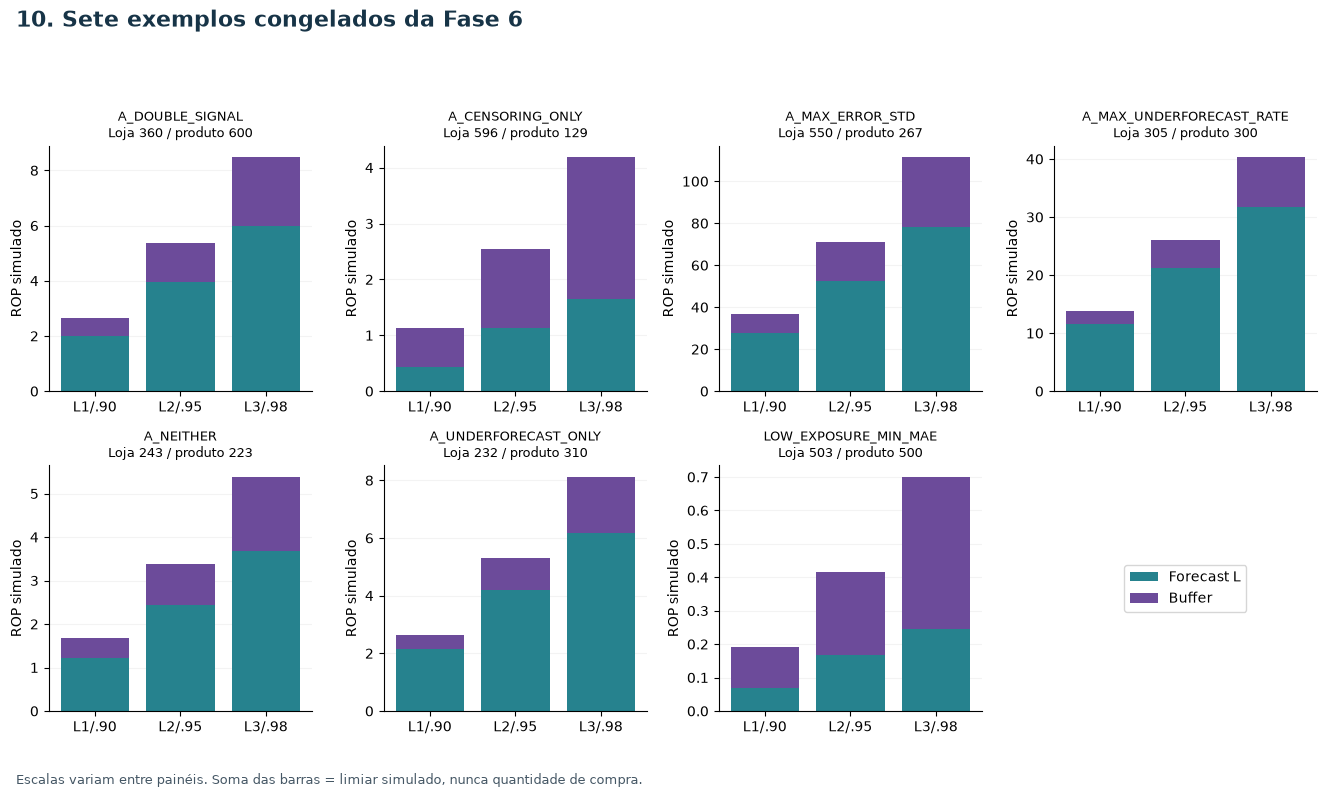

In [11]:
fig=PLOTS[9](data)
save_figure(fig,10,root)
plt.show()


## Limites e conclusão

A validação temporal revela subcobertura nos três cenários; não ajustar quantis após esse resultado. O snapshot final usa quatro folds já conhecidos em 25/06 e não tem cobertura futura comprovada. A simulação é auditável e descritiva; **os alvos não foram atingidos no fold 4**. Não recomendar política real ou compra. Consultar o relatório, protocolo e hashes. Equivalência em dias é apenas ROP dividido pela média prevista de sete dias. Sem commit ou Power BI.